# 1. Imports

In [1]:
# Base libs
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Statistics
from scipy import stats

# 2. Load data

In [3]:
# Load data
path = "../data/Telco_customer_churn.xlsx"
df = pd.read_excel(path)

# View the first rows
print(f"Data shape: {df.shape}")
print(df.head(10))

Data shape: (7043, 33)
   CustomerID  Count        Country       State         City  Zip Code  \
0  3668-QPYBK      1  United States  California  Los Angeles     90003   
1  9237-HQITU      1  United States  California  Los Angeles     90005   
2  9305-CDSKC      1  United States  California  Los Angeles     90006   
3  7892-POOKP      1  United States  California  Los Angeles     90010   
4  0280-XJGEX      1  United States  California  Los Angeles     90015   
5  4190-MFLUW      1  United States  California  Los Angeles     90020   
6  8779-QRDMV      1  United States  California  Los Angeles     90022   
7  1066-JKSGK      1  United States  California  Los Angeles     90024   
8  6467-CHFZW      1  United States  California  Los Angeles     90028   
9  8665-UTDHZ      1  United States  California  Los Angeles     90029   

                 Lat Long   Latitude   Longitude  Gender  ...        Contract  \
0  33.964131, -118.272783  33.964131 -118.272783    Male  ...  Month-to-month   


In [4]:
# Dataset information
df.info()
print("\n --- Stats ---")
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


## 3. Exploratory Data Analysis

### 3.1. Missing values
Identify missing values and understand their impact on the dataset.

--- Missing Values ---
                    Column  Missing_Count  Percentage
Churn Reason  Churn Reason           5174       73.46


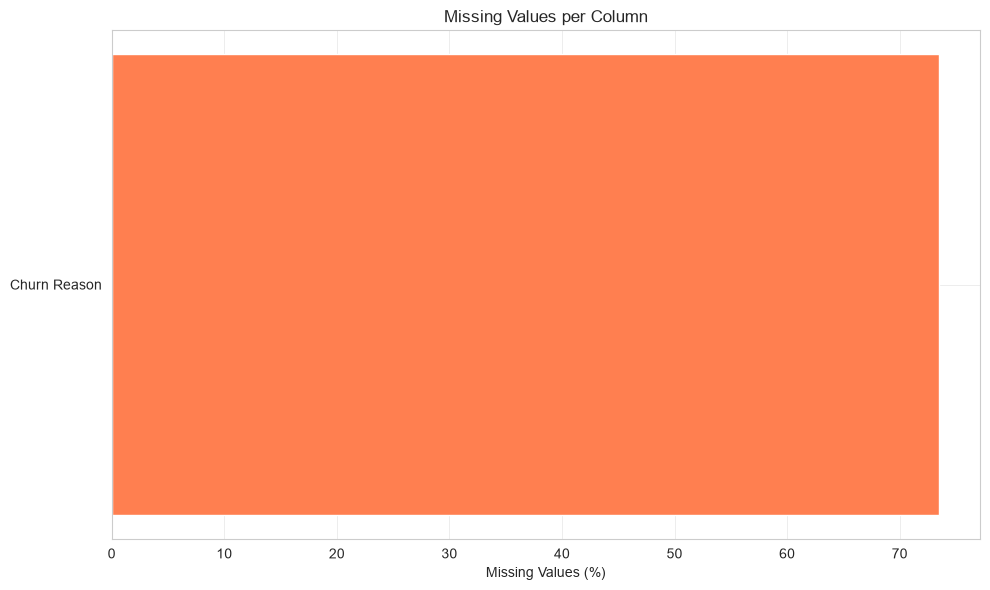

In [6]:
print("--- Missing Values ---")

missing_values = pd.DataFrame(
    {
        'Column': df.columns,
        'Missing_Count': df.isnull().sum(),
        'Percentage': ((df.isnull().sum() / len(df)) * 100).round(2)
    }
)

missing_values = missing_values[missing_values['Missing_Count'] > 0].sort_values(
    by='Percentage', ascending=False
)

if len(missing_values) > 0:
    print(missing_values)

    # Visualize
    # Visualizar missing values
    plt.figure(figsize=(10, 6))
    plt.barh(missing_values['Column'], missing_values['Percentage'], color='coral')
    plt.xlabel('Missing Values (%)')
    plt.title('Missing Values per Column')
    plt.tight_layout()
    plt.show()
else:
    print("No missing value detected!")

### 3.2. Target Analysis

Target distribution
Count:
target
0    5174
1    1869
Name: count, dtype: int64

Percentage:
No Churn (0): 73.46%
Churn (1): 26.54%


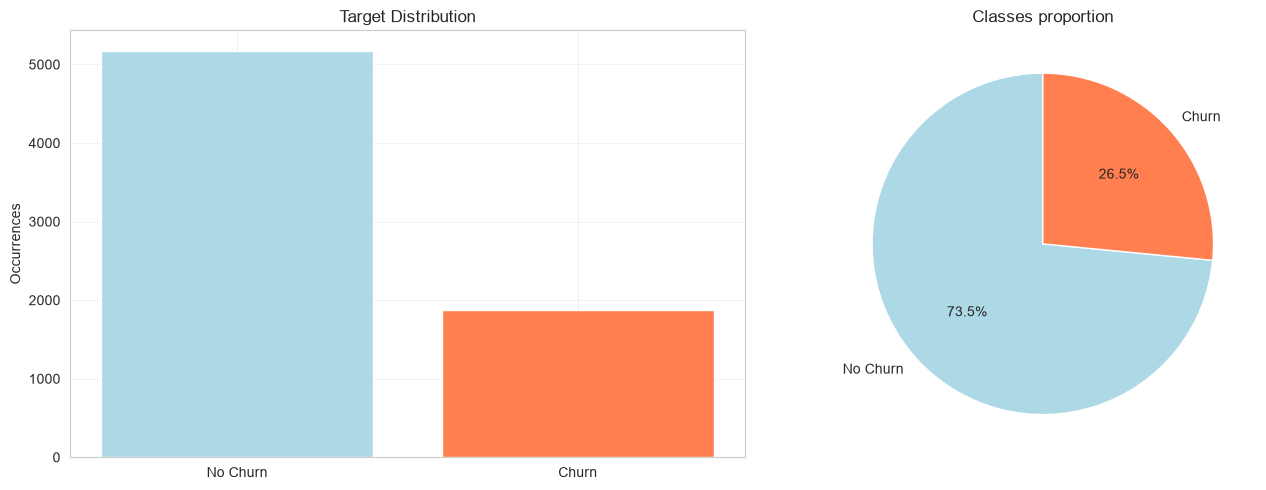


Ratio: 0.36
⚠️ Unbalanced dataset! Consider SMOTE or class_weight.


In [8]:
# Rename Churn Value column to target
df.rename(columns={'Churn Value': 'target'}, inplace=True)

print("Target distribution")
target_counts = df['target'].value_counts()
target_percentages = df['target'].value_counts(normalize=True) * 100

print("Count:")
print(target_counts)
print("\nPercentage:")
for idx, pct in target_percentages.items():
    label = "No Churn" if idx == 0 else "Churn"
    print(f"{label} ({idx}): {pct:.2f}%")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar graph
axes[0].bar(['No Churn', 'Churn'], target_counts.values, color=['lightblue', 'coral'])
axes[0].set_ylabel('Occurrences')
axes[0].set_title('Target Distribution')
axes[0].grid(axis='y', alpha=0.3)

# Pizza graph
axes[1].pie(target_counts.values, labels=['No Churn', 'Churn'],
            autopct='%1.1f%%', colors=['lightblue', 'coral'], startangle=90)
axes[1].set_title('Classes proportion')

plt.tight_layout()
plt.show()

# Check for unbalanced dataset
ratio = target_counts.min() / target_counts.max()
print(f"\nRatio: {ratio:.2f}")
if ratio < 0.5:
    print("⚠️ Unbalanced dataset! Consider SMOTE or class_weight.")
else:
    print("✓ Balanced Dataset.")